In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math
import matplotlib.patches as mp

def draw(layers, title='', colors=None, edges=True, r=0.22, fz=(7,3)):
    fig, ax = plt.subplots(figsize=fz); ax.set_xlim(0,10); ax.set_ylim(0,6); ax.axis('off')
    if title: ax.set_title(title, fontweight='bold', fontsize=11, pad=8)
    pos=[]
    for i,c in enumerate(layers):
        x=(i+1)*10/(len(layers)+1); ys=np.linspace(1.2,4.8,c) if c>1 else [3]
        pos.append([(x,y) for y in ys])
    if edges:
        for i in range(len(layers)-1):
            for p1 in pos[i]:
                for p2 in pos[i+1]: ax.plot([p1[0],p2[0]],[p1[1],p2[1]],'gray',alpha=0.25,lw=0.5)
    cols=colors or ['gold','lightgreen','lightcoral']
    for i,layer in enumerate(pos):
        c=cols[min(i,len(cols)-1)]
        for p in layer: ax.add_patch(plt.Circle(p,r,color=c,ec='black',lw=1,zorder=3))
    plt.show()

def box(x,y,w,h,label='',color='lightblue',ec='black'):
    ax=plt.gca(); ax.add_patch(mp.FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.05",
        facecolor=color,edgecolor=ec,lw=1))
    if label: ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=8,zorder=5)

def arrow(x1,y1,x2,y2,c='black',lw=1.2):
    plt.gca().annotate('',xy=(x2,y2),xytext=(x1,y1),
        arrowprops=dict(arrowstyle='->',color=c,lw=lw))

<IPython.core.display.Math object>

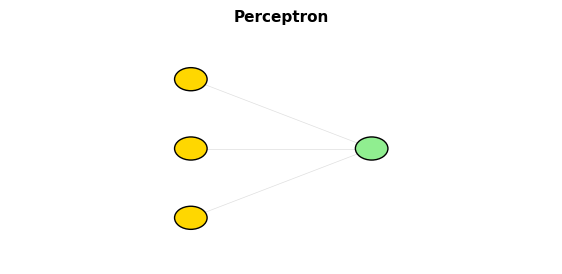

In [2]:
display(Math(r"y = \mathrm{sign}(\mathbf{w}\cdot\mathbf{x}+b)"))
draw([3,1],"Perceptron",r=0.3)

<IPython.core.display.Math object>

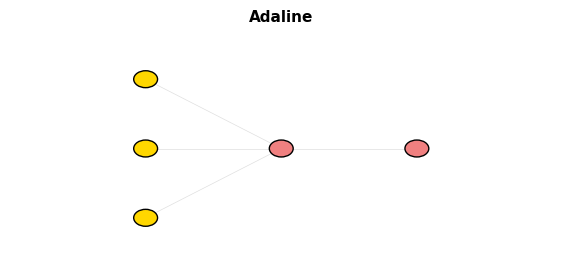

In [3]:
display(Math(r"y=\mathbf{w}\cdot\mathbf{x}+b,\quad L=\tfrac{1}{2N}\sum(y_i-t_i)^2"))
draw([3,1,1],"Adaline",colors=['gold','lightcoral','lightcoral'])

<IPython.core.display.Math object>

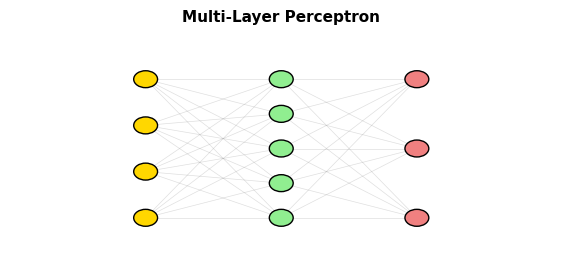

In [4]:
display(Math(r"\mathbf{h}=\sigma(W_1\mathbf{x}+\mathbf{b}_1),\quad \mathbf{y}=\mathrm{softmax}(W_2\mathbf{h}+\mathbf{b}_2)"))
draw([4,5,3],"Multi-Layer Perceptron")

<IPython.core.display.Math object>

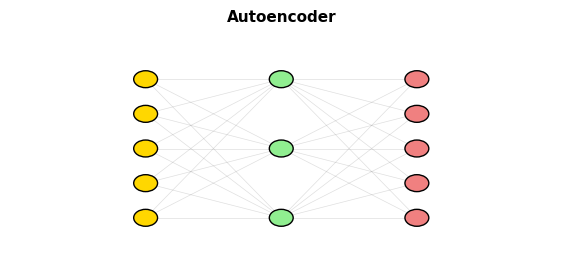

In [5]:
display(Math(r"\mathbf{h}=f(W_e\mathbf{x}+\mathbf{b}_e),\quad \hat{\mathbf{x}}=g(W_d\mathbf{h}+\mathbf{b}_d),\quad L=\|\mathbf{x}-\hat{\mathbf{x}}\|^2"))
draw([5,3,5],"Autoencoder")

<IPython.core.display.Math object>

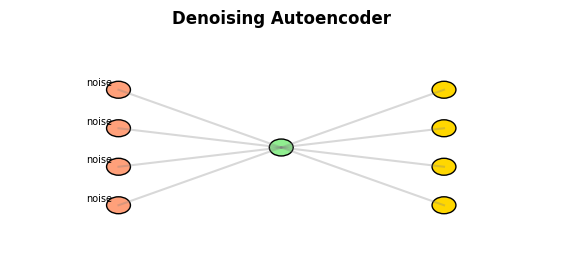

In [6]:
display(Math(r"\tilde{\mathbf{x}}=\mathbf{x}+\epsilon,\quad L=\|\mathbf{x}-g(f(\tilde{\mathbf{x}}))\|^2"))
fig,ax=plt.subplots(figsize=(7,3)); ax.set_xlim(0,10); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('Denoising Autoencoder',fontweight='bold')
xs=[(2,y) for y in np.linspace(1.5,4.5,4)]; hs=[(5,3)]; xh=[(8,y) for y in np.linspace(1.5,4.5,4)]
for p in xs:
    ax.add_patch(plt.Circle(p,0.22,color='lightsalmon',ec='black')); ax.text(p[0]-0.6,p[1]+0.1,'noise',fontsize=7)
ax.add_patch(plt.Circle(hs[0],0.22,color='lightgreen',ec='black'))
for p in xh: ax.add_patch(plt.Circle(p,0.22,color='gold',ec='black'))
for p1 in xs:
    for p2 in hs: ax.plot([p1[0],p2[0]],[p1[1],p2[1]],'gray',alpha=0.3)
for p1 in hs:
    for p2 in xh: ax.plot([p1[0],p2[0]],[p1[1],p2[1]],'gray',alpha=0.3)
plt.show()

<IPython.core.display.Math object>

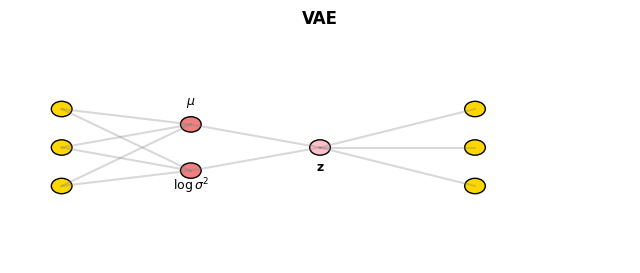

In [7]:
display(Math(r"\mu,\log\sigma^2=f_e(\mathbf{x}),\quad \mathbf{z}=\mu+\sigma\odot\epsilon,\quad L=\mathbb{E}[\log p(\mathbf{x}|\mathbf{z})]-D_{KL}(q\|p)"))
fig,ax=plt.subplots(figsize=(8,3)); ax.set_xlim(0,12); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('VAE',fontweight='bold')
x=[(1,y) for y in np.linspace(2,4,3)]; mu=[(3.5,3.6)]; lv=[(3.5,2.4)]; z=[(6,3)]; xo=[(9,y) for y in np.linspace(2,4,3)]
for p in x: ax.add_patch(plt.Circle(p,0.2,color='gold',ec='black'))
ax.add_patch(plt.Circle(mu[0],0.2,color='lightcoral',ec='black')); ax.text(3.5,4.1,r'$\mu$',ha='center',fontsize=9)
ax.add_patch(plt.Circle(lv[0],0.2,color='lightcoral',ec='black')); ax.text(3.5,1.9,r'$\log\sigma^2$',ha='center',fontsize=9)
ax.add_patch(plt.Circle(z[0],0.2,color='pink',ec='black')); ax.text(6,2.4,r'$\mathbf{z}$',ha='center',fontsize=9)
for p in xo: ax.add_patch(plt.Circle(p,0.2,color='gold',ec='black'))
for p in x:
    for q in mu+lv: ax.plot([p[0],q[0]],[p[1],q[1]],'gray',alpha=0.3)
for q in mu+lv: ax.plot([q[0],z[0][0]],[q[1],z[0][1]],'gray',alpha=0.3)
for p in xo: ax.plot([z[0][0],p[0]],[z[0][1],p[1]],'gray',alpha=0.3)
plt.show()

<IPython.core.display.Math object>

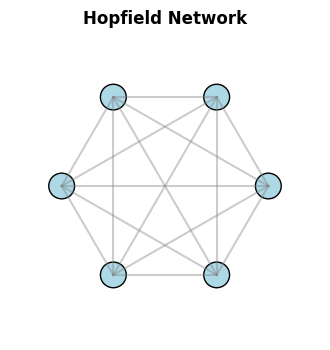

In [8]:
display(Math(r"\mathbf{s}_{t+1}=\mathrm{sign}(W\mathbf{s}_t-\boldsymbol{\theta}),\quad E=-\tfrac{1}{2}\mathbf{s}^T W\mathbf{s}-\mathbf{I}^T\mathbf{s}"))
fig,ax=plt.subplots(figsize=(4,4)); ax.set_xlim(0,6); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('Hopfield Network',fontweight='bold')
n=6; pts=[(3+2*np.cos(2*np.pi*i/n),3+2*np.sin(2*np.pi*i/n)) for i in range(n)]
for i in range(n):
    for j in range(i+1,n): ax.plot([pts[i][0],pts[j][0]],[pts[i][1],pts[j][1]],'gray',alpha=0.4)
for p in pts: ax.add_patch(plt.Circle(p,0.25,color='lightblue',ec='black'))
plt.show()

<IPython.core.display.Math object>

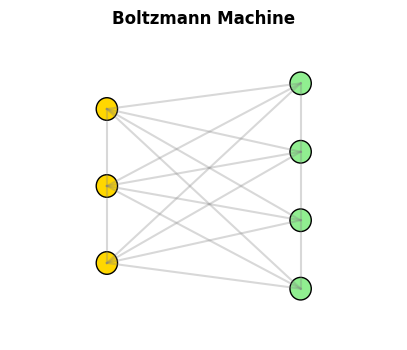

In [9]:
display(Math(r"P(\mathbf{s})=\frac{1}{Z}e^{-E(\mathbf{s})},\quad E=-\tfrac{1}{2}\mathbf{s}^T W\mathbf{s}-\mathbf{b}^T\mathbf{s}"))
fig,ax=plt.subplots(figsize=(5,4)); ax.set_xlim(0,8); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('Boltzmann Machine',fontweight='bold')
v=[(2,y) for y in np.linspace(1.5,4.5,3)]; h=[(6,y) for y in np.linspace(1,5,4)]
for p in v:
    for q in h: ax.plot([p[0],q[0]],[p[1],q[1]],'gray',alpha=0.3)
for i in range(len(v)-1): ax.plot([v[i][0],v[i+1][0]],[v[i][1],v[i+1][1]],'gray',alpha=0.3)
for i in range(len(h)-1): ax.plot([h[i][0],h[i+1][0]],[h[i][1],h[i+1][1]],'gray',alpha=0.3)
for p in v: ax.add_patch(plt.Circle(p,0.22,color='gold',ec='black'))
for p in h: ax.add_patch(plt.Circle(p,0.22,color='lightgreen',ec='black'))
plt.show()

<IPython.core.display.Math object>

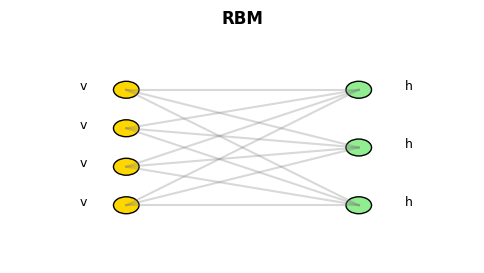

In [10]:
display(Math(r"E(\mathbf{v},\mathbf{h})=-\mathbf{b}^T\mathbf{v}-\mathbf{c}^T\mathbf{h}-\mathbf{v}^T W\mathbf{h}"))
fig,ax=plt.subplots(figsize=(6,3)); ax.set_xlim(0,8); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('RBM',fontweight='bold')
v=[(2,y) for y in np.linspace(1.5,4.5,4)]; h=[(6,y) for y in np.linspace(1.5,4.5,3)]
for p in v:
    for q in h: ax.plot([p[0],q[0]],[p[1],q[1]],'gray',alpha=0.3)
for p in v: ax.add_patch(plt.Circle(p,0.22,color='gold',ec='black')); ax.text(1.2,p[1],'v',fontsize=9)
for p in h: ax.add_patch(plt.Circle(p,0.22,color='lightgreen',ec='black')); ax.text(6.8,p[1],'h',fontsize=9)
plt.show()

<IPython.core.display.Math object>

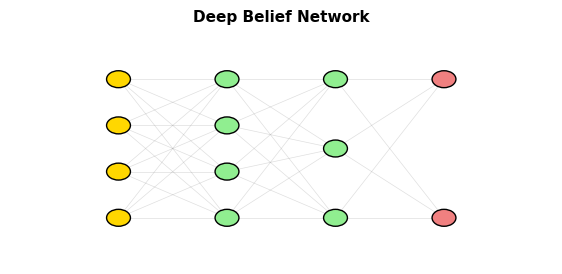

In [11]:
display(Math(r"\mathbf{h}^{(l)}=\sigma(W^{(l)}\mathbf{h}^{(l-1)}+\mathbf{b}^{(l)}),\quad \text{layer-wise RBM pretraining}"))
draw([4,4,3,2],"Deep Belief Network",colors=['gold','lightgreen','lightgreen','lightcoral'])

<IPython.core.display.Math object>

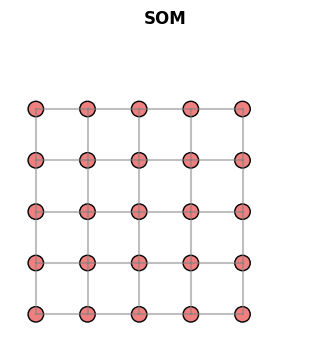

In [12]:
display(Math(r"c=\arg\min_i\|\mathbf{x}-W_i\|,\quad W_i\leftarrow W_i+\alpha h_{ci}(\mathbf{x}-W_i)"))
fig,ax=plt.subplots(figsize=(4,4)); ax.set_xlim(0,6); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('SOM',fontweight='bold')
g=5
for i in range(g):
    for j in range(g-1):
        ax.plot([i+0.5,i+0.5],[j+0.5,j+1.5],'gray',alpha=0.5)
        ax.plot([j+0.5,j+1.5],[i+0.5,i+0.5],'gray',alpha=0.5)
for i in range(g):
    for j in range(g): ax.add_patch(plt.Circle((i+0.5,j+0.5),0.15,color='lightcoral',ec='black'))
plt.show()

<IPython.core.display.Math object>

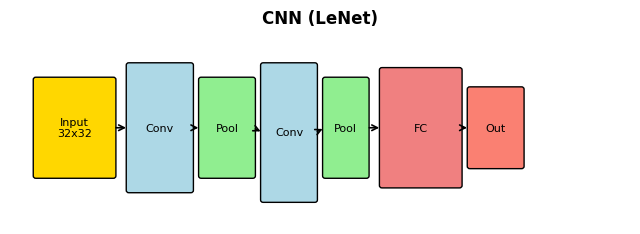

In [13]:
display(Math(r"\mathbf{y}=\mathrm{softmax}(W_{fc}\,\mathrm{pool}(\sigma(\mathrm{conv}(\mathbf{x}))+b)))"))
fig,ax=plt.subplots(figsize=(8,2.5)); ax.set_xlim(0,12); ax.set_ylim(0,4); ax.axis('off')
ax.set_title('CNN (LeNet)',fontweight='bold')
boxes=[(0.5,1,1.5,2,'Input\n32x32','gold'),(2.3,0.7,1.2,2.6,'Conv','lightblue'),
       (3.7,1,1,2,'Pool','lightgreen'),(4.9,0.5,1,2.8,'Conv','lightblue'),
       (6.1,1,0.8,2,'Pool','lightgreen'),(7.2,0.8,1.5,2.4,'FC','lightcoral'),
       (8.9,1.2,1,1.6,'Out','salmon')]
for x,y,w,h,l,c in boxes: box(x,y,w,h,l,c)
for i in range(len(boxes)-1):
    b1=boxes[i]; b2=boxes[i+1]; arrow(b1[0]+b1[2],b1[1]+b1[3]/2,b2[0],b2[1]+b2[3]/2)
plt.show()

<IPython.core.display.Math object>

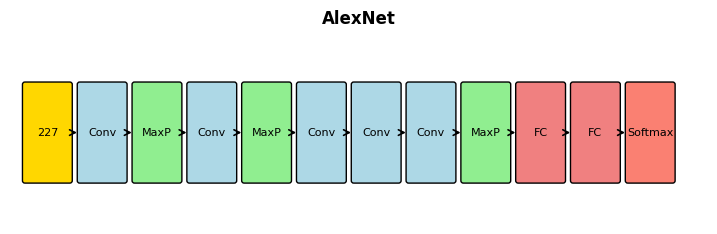

In [14]:
display(Math(r"\mathbf{y}=\mathrm{softmax}\!\left(W_{out}\,\mathrm{drop}\!\left(\sigma\!\left(W_8\cdots\mathrm{pool}\!\left(\sigma\!\left(\mathrm{conv}(\mathbf{x})\right)\right)\right)\right)\right)"))
fig,ax=plt.subplots(figsize=(9,2.5)); ax.set_xlim(0,14); ax.set_ylim(0,4); ax.axis('off')
ax.set_title('AlexNet',fontweight='bold')
labels=['227','Conv','MaxP','Conv','MaxP','Conv','Conv','Conv','MaxP','FC','FC','Softmax']
cols=['gold','lightblue','lightgreen','lightblue','lightgreen','lightblue','lightblue','lightblue','lightgreen','lightcoral','lightcoral','salmon']
for i,(l,c) in enumerate(zip(labels,cols)):
    x=0.3+i*1.1; box(x,0.9,0.9,2,l,c)
    if i>0: arrow(x-0.2,1.9,x,1.9)
plt.show()

<IPython.core.display.Math object>

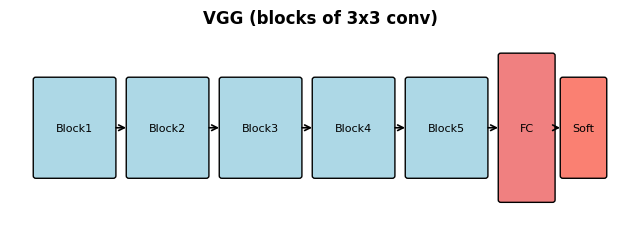

In [15]:
display(Math(r"\mathbf{y}=\mathrm{softmax}(W_{fc}\,\mathrm{flatten}(\mathrm{pool}(\sigma(\mathrm{conv}_{3\times3}(\cdot)))))"))
fig,ax=plt.subplots(figsize=(8,2.5)); ax.set_xlim(0,12); ax.set_ylim(0,4); ax.axis('off')
ax.set_title('VGG (blocks of 3x3 conv)',fontweight='bold')
blocks=[(0.5,1,1.5,2,'Block1','lightblue'),(2.3,1,1.5,2,'Block2','lightblue'),
        (4.1,1,1.5,2,'Block3','lightblue'),(5.9,1,1.5,2,'Block4','lightblue'),
        (7.7,1,1.5,2,'Block5','lightblue'),(9.5,0.5,1,3,'FC','lightcoral'),
        (10.7,1,0.8,2,'Soft','salmon')]
for x,y,w,h,l,c in blocks: box(x,y,w,h,l,c)
for i in range(len(blocks)-1):
    b1=blocks[i]; b2=blocks[i+1]; arrow(b1[0]+b1[2],b1[1]+b1[3]/2,b2[0],b2[1]+b2[3]/2)
plt.show()

<IPython.core.display.Math object>

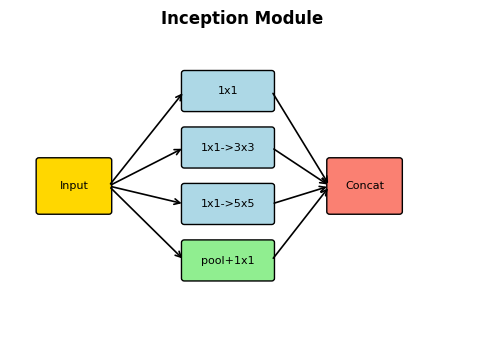

In [16]:
display(Math(r"\mathbf{y}=\mathrm{concat}([\mathrm{conv}_{1\times1},\,\mathrm{conv}_{3\times3},\,\mathrm{conv}_{5\times5},\,\mathrm{pool}])"))
fig,ax=plt.subplots(figsize=(6,4)); ax.set_xlim(0,8); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('Inception Module',fontweight='bold')
box(0.5,2.5,1.2,1,'Input','gold')
br=[(3,4.5,1.5,0.7,'1x1','lightblue'),(3,3.4,1.5,0.7,'1x1->3x3','lightblue'),
    (3,2.3,1.5,0.7,'1x1->5x5','lightblue'),(3,1.2,1.5,0.7,'pool+1x1','lightgreen')]
for x,y,w,h,l,c in br: box(x,y,w,h,l,c)
arrow(1.7,3,3,4.85); arrow(1.7,3,3,3.75); arrow(1.7,3,3,2.65); arrow(1.7,3,3,1.55)
box(5.5,2.5,1.2,1,'Concat','salmon')
for x,y,w,h,l,c in br: arrow(x+w,y+h/2,5.5,3)
plt.show()

<IPython.core.display.Math object>

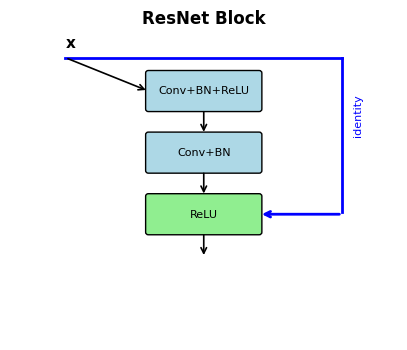

In [17]:
display(Math(r"\mathbf{y}=F(\mathbf{x},\{W_i\})+\mathbf{x}"))
fig,ax=plt.subplots(figsize=(5,4)); ax.set_xlim(0,7); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('ResNet Block',fontweight='bold')
box(2.5,4.5,2,0.7,'Conv+BN+ReLU','lightblue'); box(2.5,3.3,2,0.7,'Conv+BN','lightblue')
box(2.5,2.1,2,0.7,'ReLU','lightgreen')
arrow(1,5.5,2.5,4.85); arrow(3.5,4.5,3.5,4); arrow(3.5,3.3,3.5,2.8); arrow(3.5,2.1,3.5,1.6)
ax.plot([1,6],[5.5,5.5],'b',lw=2); ax.plot([6,6],[5.5,2.5],'b',lw=2)
ax.annotate('',xy=(4.5,2.45),xytext=(6,2.45),arrowprops=dict(arrowstyle='->',color='b',lw=2))
ax.text(6.2,4,'identity',color='b',fontsize=8,rotation=90)
ax.text(1,5.7,r'$\mathbf{x}$',fontsize=11)
plt.show()

<IPython.core.display.Math object>

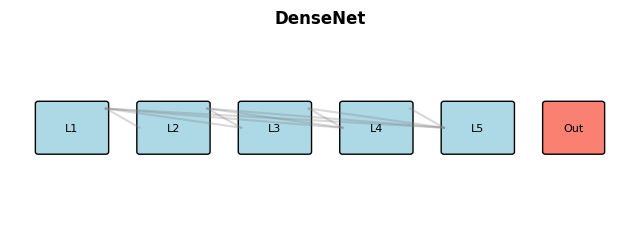

In [18]:
display(Math(r"\mathbf{x}_l=H_l([\mathbf{x}_0,\mathbf{x}_1,\ldots,\mathbf{x}_{l-1}])"))
fig,ax=plt.subplots(figsize=(8,2.5)); ax.set_xlim(0,11); ax.set_ylim(0,4); ax.axis('off')
ax.set_title('DenseNet',fontweight='bold')
bs=[(0.5,1.5,1.2,1,'L1','lightblue'),(2.3,1.5,1.2,1,'L2','lightblue'),
    (4.1,1.5,1.2,1,'L3','lightblue'),(5.9,1.5,1.2,1,'L4','lightblue'),
    (7.7,1.5,1.2,1,'L5','lightblue'),(9.5,1.5,1,1,'Out','salmon')]
for x,y,w,h,l,c in bs: box(x,y,w,h,l,c)
for i in range(len(bs)-1):
    for j in range(i+1,len(bs)-1):
        b1=bs[i]; b2=bs[j]; ax.plot([b1[0]+b1[2],b2[0]],[b1[1]+0.9,b2[1]+0.5],'gray',alpha=0.3)
plt.show()

<IPython.core.display.Math object>

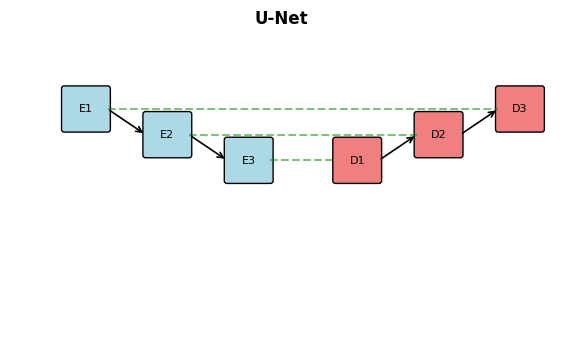

In [19]:
display(Math(r"\mathbf{d}_l=\mathrm{conv}(\mathrm{up}(\mathbf{d}_{l+1}),\,\mathrm{crop}(\mathbf{e}_l))"))
fig,ax=plt.subplots(figsize=(7,4)); ax.set_xlim(0,10); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('U-Net',fontweight='bold')
e=[(1,4.5),(2.5,4),(4,3.5)]; d=[(6,3.5),(7.5,4),(9,4.5)]
for i,(x,y) in enumerate(e): box(x,y-0.4,0.8,0.8,f'E{i+1}','lightblue')
for i,(x,y) in enumerate(d): box(x,y-0.4,0.8,0.8,f'D{i+1}','lightcoral')
for i in range(len(e)-1): arrow(e[i][0]+0.8,e[i][1],e[i+1][0],e[i+1][1])
for i in range(len(d)-1): arrow(d[i][0]+0.8,d[i][1],d[i+1][0],d[i+1][1])
for i in range(3):
    ax.plot([e[i][0]+0.8,d[2-i][0]],[e[i][1],d[2-i][1]],'g--',alpha=0.5)
plt.show()

<IPython.core.display.Math object>

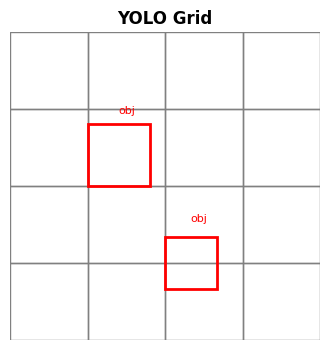

In [20]:
display(Math(r"S\times S\times(B\cdot5+C),\quad L=L_{box}+L_{obj}+L_{cls}"))
fig,ax=plt.subplots(figsize=(4,4)); ax.set_xlim(0,6); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('YOLO Grid',fontweight='bold')
for i in range(4):
    for j in range(4): ax.add_patch(plt.Rectangle((i*1.5,j*1.5),1.5,1.5,fill=False,ec='gray'))
ax.add_patch(plt.Rectangle((1.5,3),1.2,1.2,fill=False,ec='red',lw=2)); ax.text(2.1,4.4,'obj',color='red',fontsize=8)
ax.add_patch(plt.Rectangle((3,1),1,1,fill=False,ec='red',lw=2)); ax.text(3.5,2.3,'obj',color='red',fontsize=8)
plt.show()

<IPython.core.display.Math object>

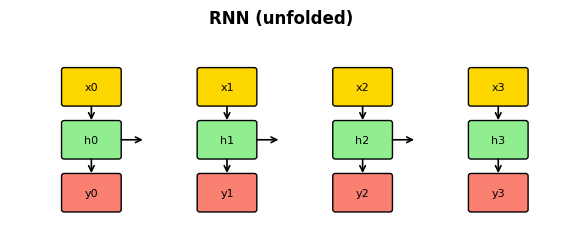

In [21]:
display(Math(r"\mathbf{h}_t=\tanh(W_{hh}\mathbf{h}_{t-1}+W_{xh}\mathbf{x}_t+\mathbf{b})"))
fig,ax=plt.subplots(figsize=(7,2.5)); ax.set_xlim(0,10); ax.set_ylim(0,4); ax.axis('off')
ax.set_title('RNN (unfolded)',fontweight='bold')
for i in range(4):
    x=1+i*2.5
    box(x,2.5,1,0.7,f'x{i}','gold')
    box(x,1.4,1,0.7,f'h{i}','lightgreen')
    box(x,0.3,1,0.7,f'y{i}','salmon')
    arrow(x+0.5,2.5,x+0.5,2.1)
    arrow(x+0.5,1.4,x+0.5,1.0)
    if i<3: arrow(x+1,1.75,x+1.5,1.75)
plt.show()

<IPython.core.display.Math object>

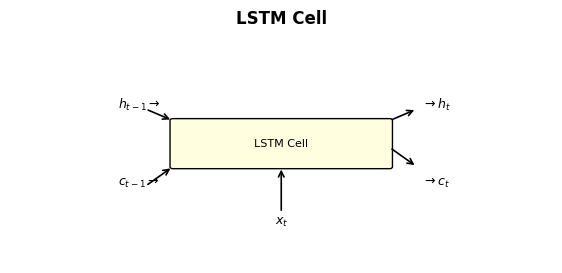

In [22]:
display(Math(r"\begin{aligned}\mathbf{i}_t&=\sigma(W_i[\mathbf{h}_{t-1},\mathbf{x}_t])\\\mathbf{f}_t&=\sigma(W_f[\mathbf{h}_{t-1},\mathbf{x}_t])\\\mathbf{o}_t&=\sigma(W_o[\mathbf{h}_{t-1},\mathbf{x}_t])\\\tilde{\mathbf{c}}_t&=\tanh(W_c[\mathbf{h}_{t-1},\mathbf{x}_t])\\\mathbf{c}_t&=\mathbf{f}_t\odot\mathbf{c}_{t-1}+\mathbf{i}_t\odot\tilde{\mathbf{c}}_t\\\mathbf{h}_t&=\mathbf{o}_t\odot\tanh(\mathbf{c}_t)\end{aligned}"))
fig,ax=plt.subplots(figsize=(7,3)); ax.set_xlim(0,10); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('LSTM Cell',fontweight='bold')
box(3,2.5,4,1.2,'LSTM Cell','lightyellow')
ax.text(2,4,r'$h_{t-1}\rightarrow$',fontsize=9); ax.text(7.6,4,r'$\rightarrow h_t$',fontsize=9)
ax.text(2,2,r'$c_{t-1}\rightarrow$',fontsize=9); ax.text(7.6,2,r'$\rightarrow c_t$',fontsize=9)
ax.text(5,1,r'$x_t$',fontsize=9,ha='center')
arrow(2.5,4,3,3.7); arrow(7,3.7,7.5,4); arrow(2.5,2,3,2.5); arrow(7,3,7.5,2.5)
arrow(5,1.3,5,2.5)
plt.show()

<IPython.core.display.Math object>

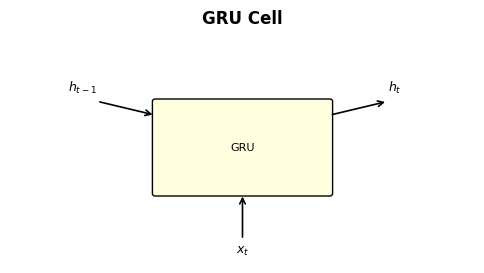

In [23]:
display(Math(r"\begin{aligned}\mathbf{z}_t&=\sigma(W_z[\mathbf{h}_{t-1},\mathbf{x}_t])\\\mathbf{r}_t&=\sigma(W_r[\mathbf{h}_{t-1},\mathbf{x}_t])\\\tilde{\mathbf{h}}_t&=\tanh(W[\mathbf{r}_t\odot\mathbf{h}_{t-1},\mathbf{x}_t])\\\mathbf{h}_t&=(1-\mathbf{z}_t)\odot\mathbf{h}_{t-1}+\mathbf{z}_t\odot\tilde{\mathbf{h}}_t\end{aligned}"))
fig,ax=plt.subplots(figsize=(6,3)); ax.set_xlim(0,8); ax.set_ylim(0,5); ax.axis('off')
ax.set_title('GRU Cell',fontweight='bold')
box(2.5,1.5,3,2,'GRU','lightyellow')
ax.text(1,3.7,r'$h_{t-1}$',fontsize=9); arrow(1.5,3.5,2.5,3.2)
ax.text(6.5,3.7,r'$h_t$',fontsize=9); arrow(5.5,3.2,6.5,3.5)
ax.text(4,0.2,r'$x_t$',fontsize=9,ha='center'); arrow(4,0.5,4,1.5)
plt.show()

<IPython.core.display.Math object>

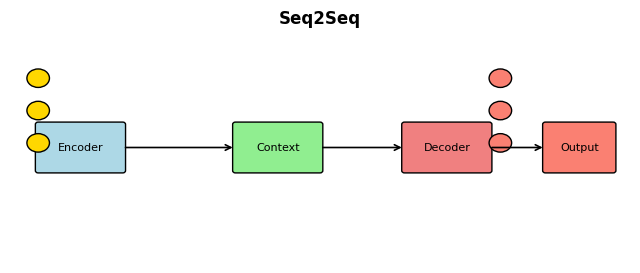

In [24]:
display(Math(r"\mathbf{c}=\mathrm{Enc}(\mathbf{x}_{1:T}),\quad \mathbf{y}_t=\mathrm{Dec}(\mathbf{y}_{<t},\mathbf{c})"))
fig,ax=plt.subplots(figsize=(8,3)); ax.set_xlim(0,11); ax.set_ylim(0,5); ax.axis('off')
ax.set_title('Seq2Seq',fontweight='bold')
box(0.5,2,1.5,1,'Encoder','lightblue'); box(4,2,1.5,1,'Context','lightgreen'); box(7,2,1.5,1,'Decoder','lightcoral'); box(9.5,2,1.2,1,'Output','salmon')
for i in range(3):
    ax.add_patch(plt.Circle((0.5,4-i*0.7),0.2,color='gold',ec='black'))
    ax.add_patch(plt.Circle((8.7,4-i*0.7),0.2,color='salmon',ec='black'))
arrow(2,2.5,4,2.5); arrow(5.5,2.5,7,2.5); arrow(8.5,2.5,9.5,2.5)
plt.show()

<IPython.core.display.Math object>

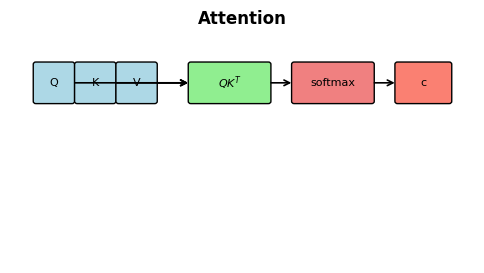

In [25]:
display(Math(r"\alpha=\mathrm{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right),\quad \mathbf{c}=\alpha V"))
fig,ax=plt.subplots(figsize=(6,3)); ax.set_xlim(0,9); ax.set_ylim(0,5); ax.axis('off')
ax.set_title('Attention',fontweight='bold')
box(0.5,3.5,0.7,0.8,'Q','lightblue'); box(1.3,3.5,0.7,0.8,'K','lightblue'); box(2.1,3.5,0.7,0.8,'V','lightblue')
box(3.5,3.5,1.5,0.8,r'$QK^T$','lightgreen'); box(5.5,3.5,1.5,0.8,'softmax','lightcoral'); box(7.5,3.5,1,0.8,'c','salmon')
arrow(1.2,3.9,3.5,3.9); arrow(2,3.9,3.5,3.9); arrow(2.8,3.9,3.5,3.9)
arrow(5,3.9,5.5,3.9); arrow(7,3.9,7.5,3.9)
plt.show()

<IPython.core.display.Math object>

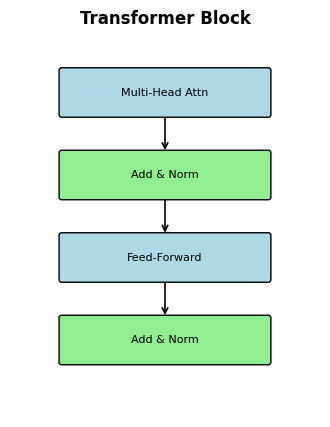

In [26]:
display(Math(r"\mathrm{Attn}(\mathbf{x})=\mathrm{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right)V,\quad \mathrm{FFN}=\max(0,\mathbf{x}W_1+b_1)W_2+b_2"))
fig,ax=plt.subplots(figsize=(4,5)); ax.set_xlim(0,6); ax.set_ylim(0,7); ax.axis('off')
ax.set_title('Transformer Block',fontweight='bold')
box(1,5.5,4,0.8,'Multi-Head Attn','lightblue')
box(1,4,4,0.8,'Add & Norm','lightgreen')
box(1,2.5,4,0.8,'Feed-Forward','lightblue')
box(1,1,4,0.8,'Add & Norm','lightgreen')
arrow(3,5.5,3,4.8); arrow(3,4,3,3.3); arrow(3,2.5,3,1.8)
plt.show()

<IPython.core.display.Math object>

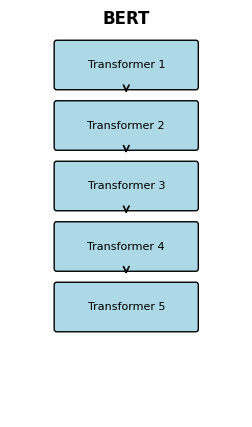

In [27]:
display(Math(r"L=-\sum\log p(x_{mask}|\mathbf{x}_{ctx})-\sum\log p(\mathrm{isNext}|\mathbf{x}_{AB})"))
fig,ax=plt.subplots(figsize=(3,5)); ax.set_xlim(0,5); ax.set_ylim(0,7); ax.axis('off')
ax.set_title('BERT',fontweight='bold')
for i in range(5):
    box(1,6-i*1.1,3,0.8,f'Transformer {i+1}','lightblue')
for i in range(4): arrow(2.5,6-i*1.1,2.5,5.9-i*1.1)
plt.show()

<IPython.core.display.Math object>

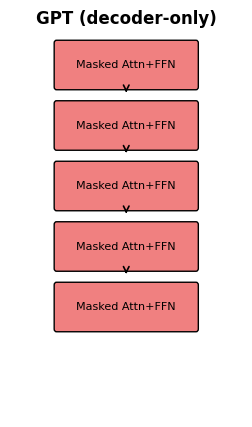

In [28]:
display(Math(r"L=-\sum_t\log p(x_t|x_{<t})"))
fig,ax=plt.subplots(figsize=(3,5)); ax.set_xlim(0,5); ax.set_ylim(0,7); ax.axis('off')
ax.set_title('GPT (decoder-only)',fontweight='bold')
for i in range(5):
    box(1,6-i*1.1,3,0.8,'Masked Attn+FFN','lightcoral')
for i in range(4): arrow(2.5,6-i*1.1,2.5,5.9-i*1.1)
plt.show()

<IPython.core.display.Math object>

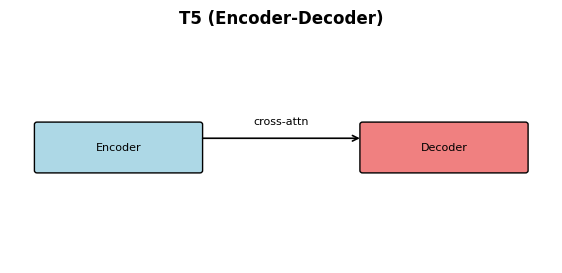

In [29]:
display(Math(r"L=-\sum_t\log p(y_t|x,y_{<t})"))
fig,ax=plt.subplots(figsize=(7,3)); ax.set_xlim(0,10); ax.set_ylim(0,5); ax.axis('off')
ax.set_title('T5 (Encoder-Decoder)',fontweight='bold')
box(0.5,2,3,1,'Encoder','lightblue'); box(6.5,2,3,1,'Decoder','lightcoral')
arrow(3.5,2.7,6.5,2.7)
ax.text(5,3,'cross-attn',ha='center',fontsize=8)
plt.show()

<IPython.core.display.Math object>

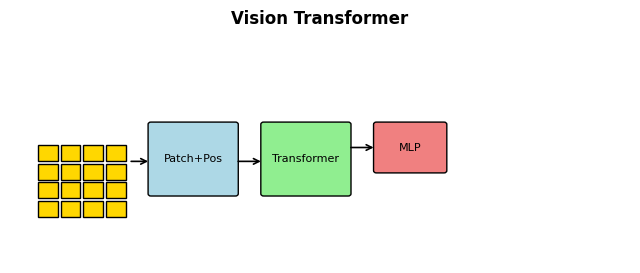

In [30]:
display(Math(r"\mathbf{z}=[\mathbf{x}_{cls};\mathbf{p}_1;\ldots;\mathbf{p}_N]+\mathbf{E}_{pos}\to\mathrm{Transformer}\to\mathrm{MLP}(\mathbf{z}_0)"))
fig,ax=plt.subplots(figsize=(8,3)); ax.set_xlim(0,11); ax.set_ylim(0,5); ax.axis('off')
ax.set_title('Vision Transformer',fontweight='bold')
for i in range(4):
    for j in range(4): ax.add_patch(plt.Rectangle((0.5+i*0.4,1+j*0.4),0.35,0.35,color='gold',ec='black'))
box(2.5,1.5,1.5,1.5,'Patch+Pos','lightblue')
box(4.5,1.5,1.5,1.5,'Transformer','lightgreen')
box(6.5,2,1.2,1,'MLP','lightcoral')
arrow(2.1,2.2,2.5,2.2); arrow(4,2.2,4.5,2.2); arrow(6,2.5,6.5,2.5)
plt.show()

<IPython.core.display.Math object>

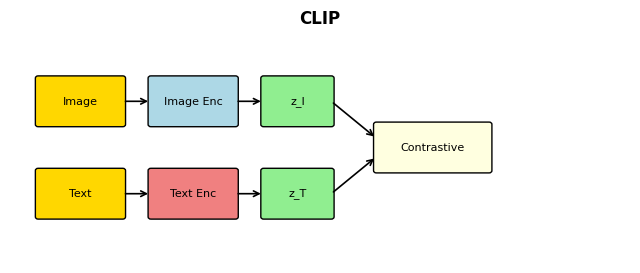

In [31]:
display(Math(r"L=-\sum_i\log\frac{\exp(\mathbf{z}_i^I\cdot\mathbf{z}_i^T/\tau)}{\sum_j\exp(\mathbf{z}_i^I\cdot\mathbf{z}_j^T/\tau)}"))
fig,ax=plt.subplots(figsize=(8,3)); ax.set_xlim(0,11); ax.set_ylim(0,5); ax.axis('off')
ax.set_title('CLIP',fontweight='bold')
box(0.5,3,1.5,1,'Image','gold'); box(2.5,3,1.5,1,'Image Enc','lightblue'); box(4.5,3,1.2,1,'z_I','lightgreen')
box(0.5,1,1.5,1,'Text','gold'); box(2.5,1,1.5,1,'Text Enc','lightcoral'); box(4.5,1,1.2,1,'z_T','lightgreen')
box(6.5,2,2,1,'Contrastive','lightyellow')
arrow(2,3.5,2.5,3.5); arrow(4,3.5,4.5,3.5); arrow(2,1.5,2.5,1.5); arrow(4,1.5,4.5,1.5)
arrow(5.7,3.5,6.5,2.7); arrow(5.7,1.5,6.5,2.3)
plt.show()

<IPython.core.display.Math object>

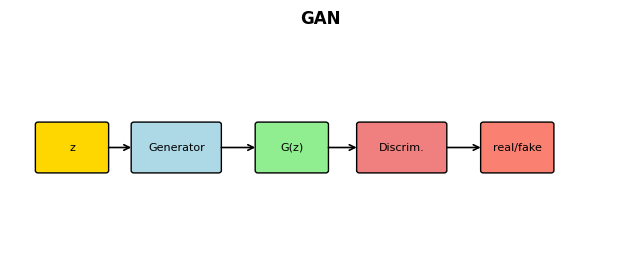

In [32]:
display(Math(r"L_D=-\mathbb{E}[\log D(\mathbf{x})]-\mathbb{E}[\log(1-D(G(\mathbf{z})))]\quad L_G=-\mathbb{E}[\log D(G(\mathbf{z}))]"))
fig,ax=plt.subplots(figsize=(8,3)); ax.set_xlim(0,11); ax.set_ylim(0,5); ax.axis('off')
ax.set_title('GAN',fontweight='bold')
box(0.5,2,1.2,1,'z','gold'); box(2.2,2,1.5,1,'Generator','lightblue'); box(4.4,2,1.2,1,'G(z)','lightgreen')
box(6.2,2,1.5,1,'Discrim.','lightcoral'); box(8.4,2,1.2,1,'real/fake','salmon')
arrow(1.7,2.5,2.2,2.5); arrow(3.7,2.5,4.4,2.5); arrow(5.6,2.5,6.2,2.5); arrow(7.7,2.5,8.4,2.5)
plt.show()

<IPython.core.display.Math object>

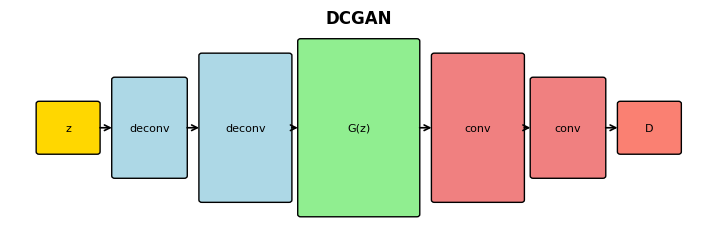

In [33]:
display(Math(r"G=\mathrm{deconv\_stack}(\mathbf{z}),\quad D=\mathrm{conv\_sigmoid\_stack}(\mathbf{x})"))
fig,ax=plt.subplots(figsize=(9,2.5)); ax.set_xlim(0,12); ax.set_ylim(0,4); ax.axis('off')
ax.set_title('DCGAN',fontweight='bold')
bs=[(0.5,1.5,1,1,'z','gold'),(1.8,1,1.2,2,'deconv','lightblue'),(3.3,0.5,1.5,3,'deconv','lightblue'),
    (5.0,0.2,2,3.6,'G(z)','lightgreen'),(7.3,0.5,1.5,3,'conv','lightcoral'),(9.0,1,1.2,2,'conv','lightcoral'),(10.5,1.5,1,1,'D','salmon')]
for x,y,w,h,l,c in bs: box(x,y,w,h,l,c)
for i in range(len(bs)-1):
    b1=bs[i]; b2=bs[i+1]; arrow(b1[0]+b1[2],b1[1]+b1[3]/2,b2[0],b2[1]+b2[3]/2)
plt.show()

<IPython.core.display.Math object>

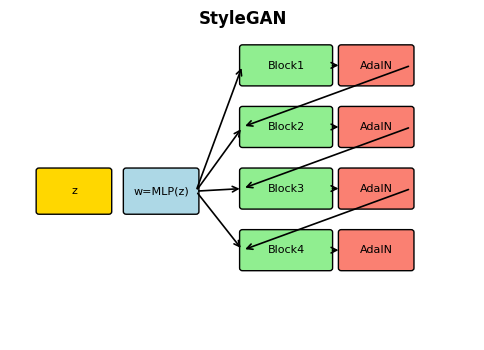

In [34]:
display(Math(r"\mathbf{w}=f(\mathbf{z}),\quad \mathbf{x}_{l+1}=\mathrm{AdaIN}(\mathrm{conv}(\mathbf{x}_l),\mathbf{w})"))
fig,ax=plt.subplots(figsize=(6,4)); ax.set_xlim(0,8); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('StyleGAN',fontweight='bold')
box(0.5,2.5,1.2,0.8,'z','gold'); box(2,2.5,1.2,0.8,'w=MLP(z)','lightblue')
for i in range(4):
    y=5-i*1.2
    box(4,y,1.5,0.7,f'Block{i+1}','lightgreen')
    box(5.7,y,1.2,0.7,'AdaIN','salmon')
    arrow(3.2,2.9,4,y+0.35)
    arrow(5.5,y+0.35,5.7,y+0.35)
    if i<3: arrow(6.9,y+0.35,4,y-0.85)
plt.show()

<IPython.core.display.Math object>

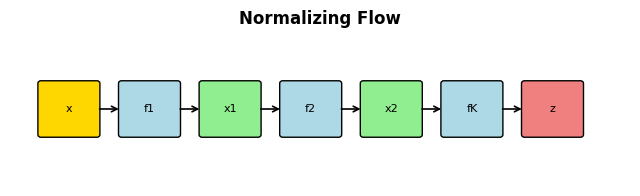

In [35]:
display(Math(r"\log p(\mathbf{x})=\log p(\mathbf{z})+\sum_{k}\log\left|\det\frac{\partial f_k}{\partial \mathbf{x}_{k-1}}\right|"))
fig,ax=plt.subplots(figsize=(8,2)); ax.set_xlim(0,10); ax.set_ylim(0,3); ax.axis('off')
ax.set_title('Normalizing Flow',fontweight='bold')
labels=['x','f1','x1','f2','x2','fK','z']
for i,l in enumerate(labels):
    c='gold' if i==0 else ('lightcoral' if i==len(labels)-1 else 'lightblue' if i%2 else 'lightgreen')
    box(0.5+i*1.3,1,0.9,1,l,c)
    if i>0: arrow(0.5+i*1.3-0.4,1.5,0.5+i*1.3,1.5)
plt.show()

<IPython.core.display.Math object>

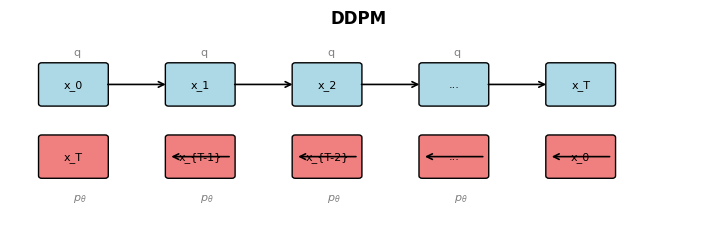

In [36]:
display(Math(r"q(\mathbf{x}_t|\mathbf{x}_0)=\mathcal{N}(\sqrt{\bar\alpha_t}\mathbf{x}_0,(1-\bar\alpha_t)\mathbf{I}),\quad L=\mathbb{E}\|\boldsymbol\epsilon-\boldsymbol\epsilon_\theta(\mathbf{x}_t,t)\|^2"))
fig,ax=plt.subplots(figsize=(9,2.5)); ax.set_xlim(0,11); ax.set_ylim(0,4); ax.axis('off')
ax.set_title('DDPM',fontweight='bold')
forward=['x_0','x_1','x_2','...','x_T']
reverse=['x_T','x_{T-1}','x_{T-2}','...','x_0']
for i,l in enumerate(forward):
    box(0.5+i*2,2.5,1,0.8,l,'lightblue')
    if i<4: arrow(1.5+i*2,2.9,0.5+(i+1)*2,2.9); ax.text(1+i*2,3.5,'q',fontsize=8,color='gray')
for i,l in enumerate(reverse):
    box(0.5+i*2,1,1,0.8,l,'lightcoral')
    if i<4: arrow(0.5+(i+1)*2+1,1.4,1.5+i*2+1,1.4); ax.text(1+i*2,0.5,r'$p_\theta$',fontsize=8,color='gray')
plt.show()

<IPython.core.display.Math object>

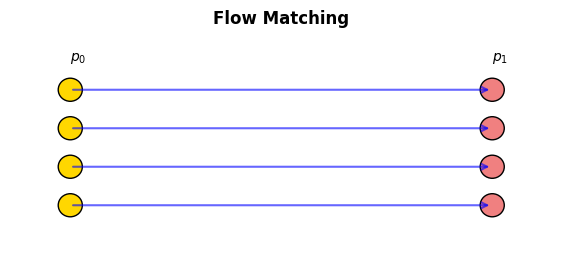

In [37]:
display(Math(r"\mathbf{u}_t=\mathbf{x}_1-\mathbf{x}_0,\quad L=\mathbb{E}_{t,\mathbf{x}_0,\mathbf{x}_1}\|v_\theta(\mathbf{x}_t,t)-\mathbf{u}_t\|^2"))
fig,ax=plt.subplots(figsize=(7,3)); ax.set_xlim(0,9); ax.set_ylim(0,4); ax.axis('off')
ax.set_title('Flow Matching',fontweight='bold')
pts0=[(1,y) for y in np.linspace(1,3,4)]; pts1=[(8,y) for y in np.linspace(1,3,4)]
for p in pts0: ax.add_patch(plt.Circle(p,0.2,color='gold',ec='black'))
for p in pts1: ax.add_patch(plt.Circle(p,0.2,color='lightcoral',ec='black'))
for p,q in zip(pts0,pts1):
    ax.annotate('',xy=q,xytext=p,arrowprops=dict(arrowstyle='->',color='blue',lw=1.5,alpha=0.6))
ax.text(1,3.5,r'$p_0$',fontsize=10); ax.text(8,3.5,r'$p_1$',fontsize=10)
plt.show()

<IPython.core.display.Math object>

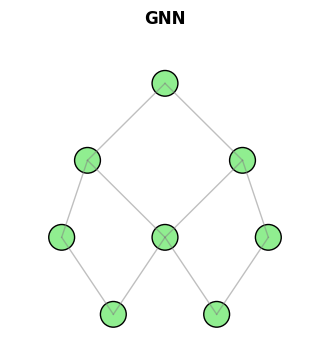

In [38]:
display(Math(r"\mathbf{h}_v^{(l+1)}=\sigma\!\left(W\sum_{u\in\mathcal{N}(v)}\mathbf{h}_u^{(l)}+\mathbf{b}\right)"))
fig,ax=plt.subplots(figsize=(4,4)); ax.set_xlim(0,6); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('GNN',fontweight='bold')
pts=[(3,5),(1.5,3.5),(4.5,3.5),(1,2),(3,2),(5,2),(2,0.5),(4,0.5)]
edges=[(0,1),(0,2),(1,3),(1,4),(2,5),(2,4),(4,6),(4,7),(3,6),(5,7)]
for i,j in edges: ax.plot([pts[i][0],pts[j][0]],[pts[i][1],pts[j][1]],'gray',alpha=0.5,lw=1)
for p in pts: ax.add_patch(plt.Circle(p,0.25,color='lightgreen',ec='black'))
plt.show()

<IPython.core.display.Math object>

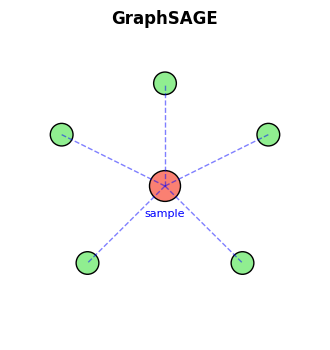

In [39]:
display(Math(r"\mathbf{h}_v=\mathrm{ReLU}\!\left(W_1\mathbf{h}_v+W_2\cdot\mathrm{mean}_{u\in\mathcal{S}(v)}\mathbf{h}_u\right)"))
fig,ax=plt.subplots(figsize=(4,4)); ax.set_xlim(0,6); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('GraphSAGE',fontweight='bold')
center=(3,3); neighbors=[(3,5),(1,4),(5,4),(1.5,1.5),(4.5,1.5)]
for p in neighbors: ax.plot([center[0],p[0]],[center[1],p[1]],'b--',alpha=0.5,lw=1)
ax.add_patch(plt.Circle(center,0.3,color='salmon',ec='black'))
for p in neighbors: ax.add_patch(plt.Circle(p,0.22,color='lightgreen',ec='black'))
ax.text(3,2.4,'sample',fontsize=8,color='blue',ha='center')
plt.show()

<IPython.core.display.Math object>

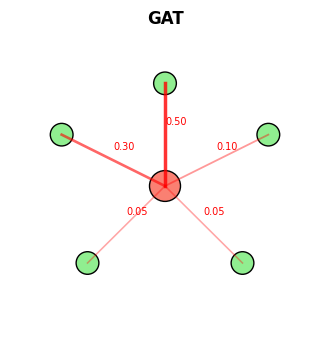

In [40]:
display(Math(r"\alpha_{vu}=\mathrm{softmax}_u\!\left(\mathrm{LeakyReLU}(\mathbf{a}^T[W\mathbf{h}_v\|W\mathbf{h}_u])\right),\quad \mathbf{h}_v=\sigma\!\left(\sum_u\alpha_{vu}W\mathbf{h}_u\right)"))
fig,ax=plt.subplots(figsize=(4,4)); ax.set_xlim(0,6); ax.set_ylim(0,6); ax.axis('off')
ax.set_title('GAT',fontweight='bold')
center=(3,3); neighbors=[(3,5),(1,4),(5,4),(1.5,1.5),(4.5,1.5)]
ws=[0.5,0.3,0.1,0.05,0.05]
for p,w in zip(neighbors,ws):
    ax.plot([center[0],p[0]],[center[1],p[1]],'r',alpha=0.3+w,lw=1+3*w)
ax.add_patch(plt.Circle(center,0.3,color='salmon',ec='black'))
for p,w in zip(neighbors,ws):
    ax.add_patch(plt.Circle(p,0.22,color='lightgreen',ec='black'))
    ax.text((center[0]+p[0])/2,(center[1]+p[1])/2+0.2,f'{w:.2f}',fontsize=7,color='red')
plt.show()

<IPython.core.display.Math object>

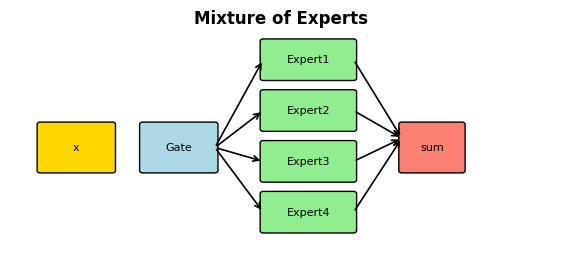

In [41]:
display(Math(r"g=\mathrm{softmax}(W_g\mathbf{x}),\quad \mathbf{y}=\sum_{i\in\mathrm{top}\text{-}k}g_i\cdot\mathrm{Expert}_i(\mathbf{x})"))
fig,ax=plt.subplots(figsize=(7,3)); ax.set_xlim(0,9); ax.set_ylim(0,5); ax.axis('off')
ax.set_title('Mixture of Experts',fontweight='bold')
box(0.5,2,1.2,1,'x','gold'); box(2.2,2,1.2,1,'Gate','lightblue')
for i in range(4):
    box(4.2,4-i*1.1,1.5,0.8,f'Expert{i+1}','lightgreen')
    arrow(3.4,2.5,4.2,4-i*1.1+0.4)
box(6.5,2,1,1,'sum','salmon')
for i in range(4): arrow(5.7,4-i*1.1+0.4,6.5,2.7)
plt.show()

<IPython.core.display.Math object>

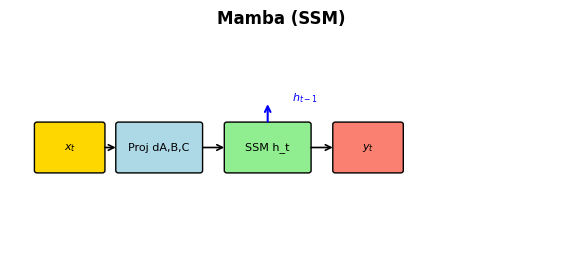

In [42]:
display(Math(r"\begin{aligned}\Delta_t&=\mathrm{softplus}(W_\Delta\mathbf{x}_t)\\\bar{A}_t&=\exp(\Delta_t A),\quad \bar{B}_t=\Delta_t B(\mathbf{x}_t)\\\mathbf{h}_t&=\bar{A}_t\mathbf{h}_{t-1}+\bar{B}_t\mathbf{x}_t\\\mathbf{y}_t&=C(\mathbf{x}_t)\mathbf{h}_t\end{aligned}"))
fig,ax=plt.subplots(figsize=(7,3)); ax.set_xlim(0,10); ax.set_ylim(0,5); ax.axis('off')
ax.set_title('Mamba (SSM)',fontweight='bold')
box(0.5,2,1.2,1,r'$x_t$','gold'); box(2,2,1.5,1,'Proj dA,B,C','lightblue')
box(4,2,1.5,1,'SSM h_t','lightgreen'); box(6,2,1.2,1,r'$y_t$','salmon')
arrow(1.7,2.5,2,2.5); arrow(3.5,2.5,4,2.5); arrow(5.5,2.5,6,2.5)
ax.annotate('',xy=(4.75,3.5),xytext=(4.75,3),arrowprops=dict(arrowstyle='->',color='blue',lw=1.5))
ax.text(5.2,3.5,r'$h_{t-1}$',fontsize=8,color='blue')
plt.show()

<IPython.core.display.Math object>

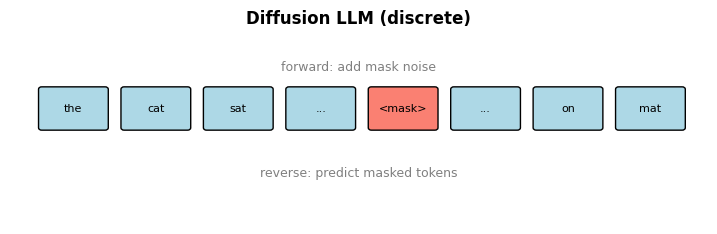

In [43]:
display(Math(r"q(\mathbf{x}_t|\mathbf{x}_0)=\mathrm{Cat}\!\left((1-\beta_t)\mathbf{x}_0+\tfrac{\beta_t}{K}\mathbf{1}\right),\quad L=\mathbb{E}\!\left[-\sum\mathbf{x}_0\cdot\log \hat{\mathbf{x}}_\theta(\mathbf{x}_t,t)\right]"))
fig,ax=plt.subplots(figsize=(9,2.5)); ax.set_xlim(0,11); ax.set_ylim(0,4); ax.axis('off')
ax.set_title('Diffusion LLM (discrete)',fontweight='bold')
toks=['the','cat','sat','...','<mask>','...','on','mat']
for i,t in enumerate(toks):
    c='salmon' if t=='<mask>' else 'lightblue'
    box(0.5+i*1.3,2,1,0.8,t,c)
ax.text(5.5,1,'reverse: predict masked tokens',fontsize=9,color='gray',ha='center')
ax.text(5.5,3.2,'forward: add mask noise',fontsize=9,color='gray',ha='center')
plt.show()